In [2]:
!pip install -q ultralytics kagglehub

import kagglehub

# Download SeaDronesSee dataset
path = kagglehub.dataset_download("ubiratanfilho/sds-dataset")

print("Dataset downloaded to:", path)

Dataset downloaded to: /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1


In [3]:
!pip install -q ultralytics

In [4]:
import os
import json
import shutil
from pathlib import Path

from ultralytics import YOLO

print("Setup complete")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Setup complete


In [5]:
BASE = Path(
    "/root/.cache/kagglehub/datasets/"
    "ubiratanfilho/sds-dataset/versions/1/compressed"
)

print("Dataset exists:", BASE.exists())
print("Dataset path:", BASE)

Dataset exists: True
Dataset path: /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed


In [ ]:
print("Dataset contents:")
print(os.listdir(BASE))

print("\nImages:")
print(os.listdir(BASE / "images"))

print("\nAnnotations:")
print(os.listdir(BASE / "annotations"))

Dataset contents:
['images', 'annotations']

Images:
['val', 'test', 'train']

Annotations:
['train_images_metadata.csv', 'instances_train.json', 'instances_val.json', 'val_images_metadata.csv']


In [ ]:
for split in ["train", "val", "test"]:

    folder = BASE / "images" / split

    images = [
        f for f in folder.iterdir()
        if f.is_file()
    ]

    print(split, "images:", len(images))

train images: 8930
val images: 1547
test images: 3750


In [ ]:
for split in ["train", "val"]:

    json_file = (
        BASE /
        "annotations" /
        f"instances_{split}.json"
    )

    with open(json_file, "r") as f:
        data = json.load(f)

    print("\n", split)
    print("Images:", len(data["images"]))
    print("Annotations:", len(data["annotations"]))
    print("Classes:")

    for category in data["categories"]:
        print(
            category["id"],
            "->",
            category["name"]
        )


 train
Images: 8930
Annotations: 57760
Classes:
0 -> ignored
1 -> swimmer
2 -> boat
3 -> jetski
4 -> life_saving_appliances
5 -> buoy

 val
Images: 1547
Annotations: 9630
Classes:
0 -> ignored
1 -> swimmer
2 -> boat
3 -> jetski
4 -> life_saving_appliances
5 -> buoy


In [ ]:
YOLO_DATASET = Path("/content/seedrones_yolo")

for split in ["train", "val"]:

    (YOLO_DATASET / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (YOLO_DATASET / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )

print("YOLO dataset directory created:")
print(YOLO_DATASET)

YOLO dataset directory created:
/content/seedrones_yolo


In [ ]:
def convert_coco_to_yolo(json_file, split):

    print(f"\nConverting {split}...")

    with open(json_file, "r") as f:
        coco = json.load(f)

    # Images
    images = {
        img["id"]: img
        for img in coco["images"]
    }

    # Categories
    categories = {
        cat["id"]: cat
        for cat in coco["categories"]
    }

    # Create continuous YOLO class IDs
    category_ids = sorted(categories.keys())

    category_to_yolo = {
        category_id: i
        for i, category_id in enumerate(category_ids)
    }

    print("\nClasses:")

    for category_id in category_ids:

        print(
            category_to_yolo[category_id],
            "->",
            categories[category_id]["name"]
        )

    # Group annotations by image
    annotations_by_image = {}

    for annotation in coco["annotations"]:

        image_id = annotation["image_id"]

        if image_id not in annotations_by_image:
            annotations_by_image[image_id] = []

        annotations_by_image[image_id].append(
            annotation
        )

    copied_images = 0
    created_labels = 0

    for image_id, image_info in images.items():

        filename = image_info["file_name"]

        # Some COCO datasets store paths.
        # We use only the actual filename.
        filename_only = Path(filename).name

        source = (
            BASE /
            "images" /
            split /
            filename_only
        )

        if not source.exists():

            print(
                "Missing image:",
                filename_only
            )

            continue

        # Copy image
        destination = (
            YOLO_DATASET /
            "images" /
            split /
            filename_only
        )

        shutil.copy2(
            source,
            destination
        )

        copied_images += 1

        # Label filename
        label_file = (
            YOLO_DATASET /
            "labels" /
            split /
            f"{source.stem}.txt"
        )

        with open(label_file, "w") as f:

            for annotation in annotations_by_image.get(
                image_id,
                []
            ):

                x, y, w, h = annotation["bbox"]

                image_width = image_info["width"]
                image_height = image_info["height"]

                # COCO -> YOLO
                x_center = (
                    x + w / 2
                ) / image_width

                y_center = (
                    y + h / 2
                ) / image_height

                width = (
                    w / image_width
                )

                height = (
                    h / image_height
                )

                class_id = category_to_yolo[
                    annotation["category_id"]
                ]

                f.write(
                    f"{class_id} "
                    f"{x_center:.6f} "
                    f"{y_center:.6f} "
                    f"{width:.6f} "
                    f"{height:.6f}\n"
                )

                created_labels += 1

    print(
        f"{split}: copied {copied_images} images"
    )

    print(
        f"{split}: created {created_labels} objects"
    )

    return category_to_yolo, categories

In [ ]:
train_json = (
    BASE /
    "annotations" /
    "instances_train.json"
)

val_json = (
    BASE /
    "annotations" /
    "instances_val.json"
)

train_mapping, train_categories = (
    convert_coco_to_yolo(
        train_json,
        "train"
    )
)

val_mapping, val_categories = (
    convert_coco_to_yolo(
        val_json,
        "val"
    )
)


Converting train...

Classes:
0 -> ignored
1 -> swimmer
2 -> boat
3 -> jetski
4 -> life_saving_appliances
5 -> buoy
train: copied 8930 images
train: created 57760 objects

Converting val...

Classes:
0 -> ignored
1 -> swimmer
2 -> boat
3 -> jetski
4 -> life_saving_appliances
5 -> buoy
val: copied 1547 images
val: created 9630 objects


In [ ]:
for split in ["train", "val"]:

    image_folder = (
        YOLO_DATASET /
        "images" /
        split
    )

    label_folder = (
        YOLO_DATASET /
        "labels" /
        split
    )

    images = list(image_folder.glob("*"))
    labels = list(label_folder.glob("*.txt"))

    print(
        split,
        "images:",
        len(images),
        "labels:",
        len(labels)
    )

train images: 8930 labels: 8930
val images: 1547 labels: 1547


In [ ]:
names = [
    train_categories[c]["name"]
    for c in sorted(train_categories.keys())
]

print("YOLO classes:")
for i, name in enumerate(names):
    print(i, "->", name)

YOLO classes:
0 -> ignored
1 -> swimmer
2 -> boat
3 -> jetski
4 -> life_saving_appliances
5 -> buoy


In [ ]:
yaml_content = f"""path: {YOLO_DATASET}
train: images/train
val: images/val

names:
"""

for i, name in enumerate(names):
    yaml_content += f"  {i}: {name}\n"

DATA_YAML = YOLO_DATASET / "data.yaml"

with open(DATA_YAML, "w") as f:
    f.write(yaml_content)

print("\nCreated:")
print(DATA_YAML)

print("\nContents:\n")
print(DATA_YAML.read_text())


Created:
/content/seedrones_yolo/data.yaml

Contents:

path: /content/seedrones_yolo
train: images/train
val: images/val

names:
  0: ignored
  1: swimmer
  2: boat
  3: jetski
  4: life_saving_appliances
  5: buoy



In [ ]:
print("data.yaml:", DATA_YAML.exists())

print(
    "Train images:",
    (YOLO_DATASET / "images/train").exists()
)

print(
    "Val images:",
    (YOLO_DATASET / "images/val").exists()
)

print(
    "Train labels:",
    (YOLO_DATASET / "labels/train").exists()
)

print(
    "Val labels:",
    (YOLO_DATASET / "labels/val").exists()
)

data.yaml: True
Train images: True
Val images: True
Train labels: True
Val labels: True


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data="/content/seedrones_yolo/data.yaml",
    epochs=5,
    imgsz=640,
    batch=16,
    device=0,
    workers=4,
    project="/content/seedrones_training",
    name="seedrones_gpu_test"
)

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/seedrones_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=seedrones_gpu_test, nbs=64, n

RuntimeError: Dataset '/content/seedrones_yolo/data.yaml' error ❌ '/content/seedrones_yolo/data.yaml' does not exist

In [7]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
# ============================================================
# EVALUATE TRAINED SEADRONESSEE YOLO MODEL
# ============================================================

from ultralytics import YOLO
import os

# ------------------------------------------------------------
# MODEL PATH
# ------------------------------------------------------------

MODEL_PATH = (
    "/content/drive/MyDrive/ResearchProject/"
    "models/seedrones/"
    "best_seedrones_detector.pt"
)

print("Model exists:", os.path.exists(MODEL_PATH))
print("Model path:", MODEL_PATH)


# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = YOLO(MODEL_PATH)

print("\nModel loaded successfully")


# ------------------------------------------------------------
# VALIDATE MODEL
# ------------------------------------------------------------

metrics = model.val(
    plots=True
)


# ------------------------------------------------------------
# PRINT ACCURACY METRICS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SEADRONESSEE YOLO MODEL PERFORMANCE")
print("=" * 60)

print(f"\nPrecision       : {metrics.box.mp:.4f}")
print(f"Recall          : {metrics.box.mr:.4f}")

print(f"\nmAP@50          : {metrics.box.map50:.4f}")
print(f"mAP@75          : {metrics.box.map75:.4f}")
print(f"mAP@50-95       : {metrics.box.map:.4f}")

print("\nPercentage form:")

print(
    f"Precision       : "
    f"{metrics.box.mp * 100:.2f}%"
)

print(
    f"Recall          : "
    f"{metrics.box.mr * 100:.2f}%"
)

print(
    f"mAP@50          : "
    f"{metrics.box.map50 * 100:.2f}%"
)

print(
    f"mAP@50-95       : "
    f"{metrics.box.map * 100:.2f}%"
)


# ------------------------------------------------------------
# PER-CLASS RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PER-CLASS PERFORMANCE")
print("=" * 60)

for i, value in enumerate(metrics.box.maps):

    print(
        f"Class {i}: "
        f"mAP@50-95 = {value:.4f}"
    )


# ------------------------------------------------------------
# OUTPUT LOCATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("VALIDATION COMPLETED")
print("=" * 60)

print("\nResults saved by YOLO in the validation output folder.")

Model exists: True
Model path: /content/drive/MyDrive/ResearchProject/models/seedrones/best_seedrones_detector.pt

Model loaded successfully
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2675.2±1156.4 MB/s, size: 883.0 KB)
val: Scanning /content/seedrones_yolo/labels/val... 1547 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1547/1547 1.6Kit/s 0.9s
val: New cache created: /content/seedrones_yolo/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 97/97 1.1it/s 1:30
                   all       1547       9630      0.806      0.598      0.618      0.339
               swimmer       1286       6206      0.743      0.672      0.648      0.236
                  boat        915       2214      0.912      0.884      0.907      0.607
                j

Testing image: /root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/images/val/10435.jpg


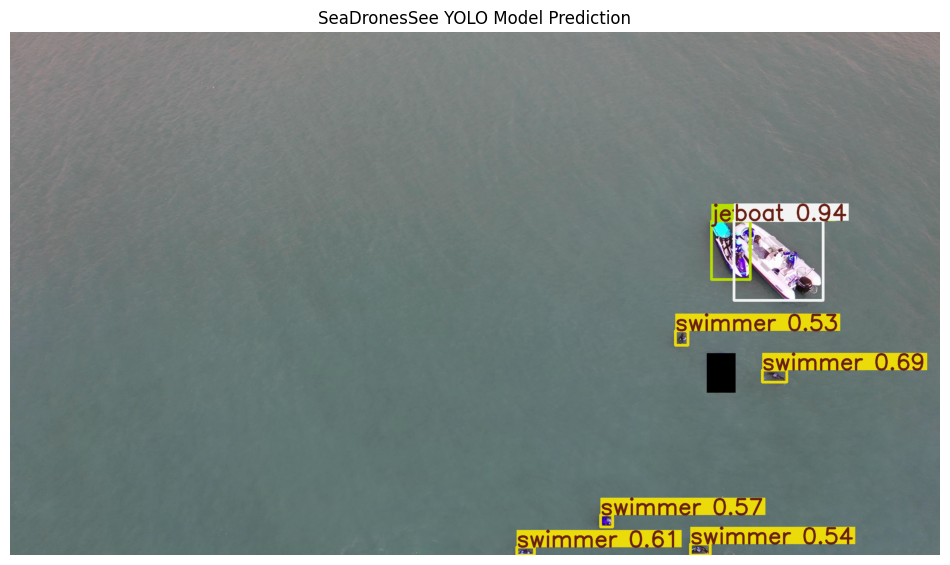


Detected objects:
boat : 0.937
jetski : 0.806
swimmer : 0.688
swimmer : 0.605
swimmer : 0.575
swimmer : 0.538
swimmer : 0.528


In [14]:
from ultralytics import YOLO
import glob
import matplotlib.pyplot as plt

# Load trained model
model = YOLO(
    "/content/drive/MyDrive/ResearchProject/models/seedrones/best_seedrones_detector.pt"
)

# Get validation images
val_images = sorted(
    glob.glob(
        "/root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/images/val/*"
    )
)

# Select another image
sample = val_images[24]

print("Testing image:", sample)

# Prediction
results = model.predict(
    source=sample,
    conf=0.25,
    verbose=False
)

# Display
img = results[0].plot()

plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off")
plt.title("SeaDronesSee YOLO Model Prediction")
plt.show()

# Detected objects
print("\nDetected objects:")

for box in results[0].boxes:
    cls = int(box.cls[0])
    conf = float(box.conf[0])
    print(f"{results[0].names[cls]} : {conf:.3f}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
%%writefile /content/drive/MyDrive/ResearchProject/ais/fusion_detector.py

import os
import glob
import pandas as pd
from ultralytics import YOLO


class FusionDetector:
    def __init__(self, radar_model_path, visual_model_path):
        self.radar_model = YOLO(radar_model_path)
        self.visual_model = YOLO(visual_model_path)

    def detect_folder(self, radar_folder, camera_folder, output_csv):
        detections = []

        # Read all radar images
        radar_images = sorted(
            glob.glob(os.path.join(radar_folder, '*.png')) +
            glob.glob(os.path.join(radar_folder, '*.jpg')) +
            glob.glob(os.path.join(radar_folder, '*.jpeg'))
        )

        # Read all camera images
        camera_images = sorted(
            glob.glob(os.path.join(camera_folder, '*.png')) +
            glob.glob(os.path.join(camera_folder, '*.jpg')) +
            glob.glob(os.path.join(camera_folder, '*.jpeg'))
        )

        total_frames = max(len(radar_images), len(camera_images))

        for frame in range(total_frames):

            # -----------------------------
            # Radar detections (HRSID)
            # -----------------------------
            if frame < len(radar_images):
                radar_results = self.radar_model.predict(
                    source=radar_images[frame],
                    conf=0.25,
                    verbose=False
                )

                for r in radar_results:
                    for box in r.boxes:
                        x1, y1, x2, y2 = box.xyxy[0].tolist()

                        detections.append({
                            'frame': frame,
                            'class': 'ship',
                            'source': 'radar',
                            'confidence': float(box.conf[0]),
                            'x1': x1,
                            'y1': y1,
                            'x2': x2,
                            'y2': y2,
                            'cx': (x1 + x2) / 2,
                            'cy': (y1 + y2) / 2
                        })

            # -----------------------------
            # Camera detections (SeaDronesSee)
            # -----------------------------
            if frame < len(camera_images):
                visual_results = self.visual_model.predict(
                    source=camera_images[frame],
                    conf=0.25,
                    verbose=False
                )

                for r in visual_results:
                    for box in r.boxes:
                        cls = int(box.cls[0])
                        class_name = r.names[cls]

                        x1, y1, x2, y2 = box.xyxy[0].tolist()

                        detections.append({
                            'frame': frame,
                            'class': class_name,
                            'source': 'camera',
                            'confidence': float(box.conf[0]),
                            'x1': x1,
                            'y1': y1,
                            'x2': x2,
                            'y2': y2,
                            'cx': (x1 + x2) / 2,
                            'cy': (y1 + y2) / 2
                        })

        df = pd.DataFrame(detections)

        if len(df) == 0:
            print('No detections found')
            return df

        # Tracker-compatible format
        df = df[
            [
                'frame',
                'class',
                'source',
                'confidence',
                'x1',
                'y1',
                'x2',
                'y2',
                'cx',
                'cy'
            ]
        ]

        os.makedirs(os.path.dirname(output_csv), exist_ok=True)
        df.to_csv(output_csv, index=False)

        print('Fusion completed successfully')
        print(f'Total detections: {len(df)}')
        print(f'Output saved to: {output_csv}')

        return df


# -------------------------------------------------------
# Los Angeles configuration
# -------------------------------------------------------

RADAR_MODEL = '/content/drive/MyDrive/ResearchProject/models/best_model/best_ship_detector.pt'
VISUAL_MODEL = '/content/drive/MyDrive/ResearchProject/models/seedrones/best_seedrones_detector.pt'

RADAR_FOLDER = "/content/drive/MyDrive/ResearchProject/dataset/images/val"
CAMERA_FOLDER = "/root/.cache/kagglehub/datasets/ubiratanfilho/sds-dataset/versions/1/compressed/images/val"

OUTPUT = '/content/drive/MyDrive/ResearchProject/ais/fused_detections.csv'


if __name__ == '__main__':
    detector = FusionDetector(
        RADAR_MODEL,
        VISUAL_MODEL
    )

    result = detector.detect_folder(
        RADAR_FOLDER,
        CAMERA_FOLDER,
        OUTPUT
    )

    print(result.head())

Overwriting /content/drive/MyDrive/ResearchProject/ais/fusion_detector.py



Testing image: /content/drive/MyDrive/ResearchProject/dataset/images/test/P0001_1200_2000_8400_9200.png


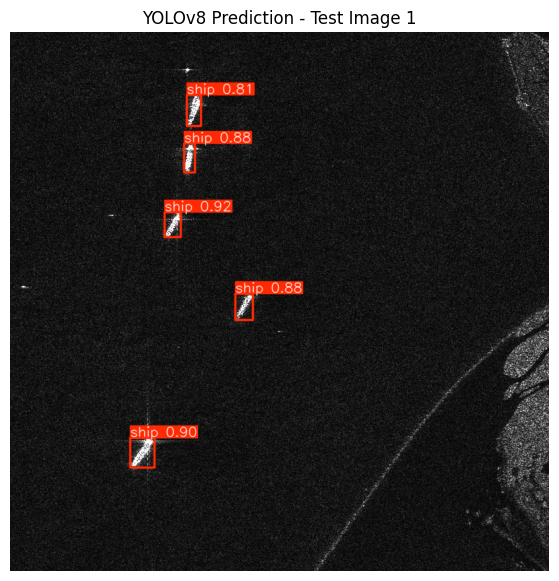

Detected objects:
ship : 0.919
ship : 0.899
ship : 0.885
ship : 0.882
ship : 0.811

Testing image: /content/drive/MyDrive/ResearchProject/dataset/images/test/P0003_0_800_8400_9200.png


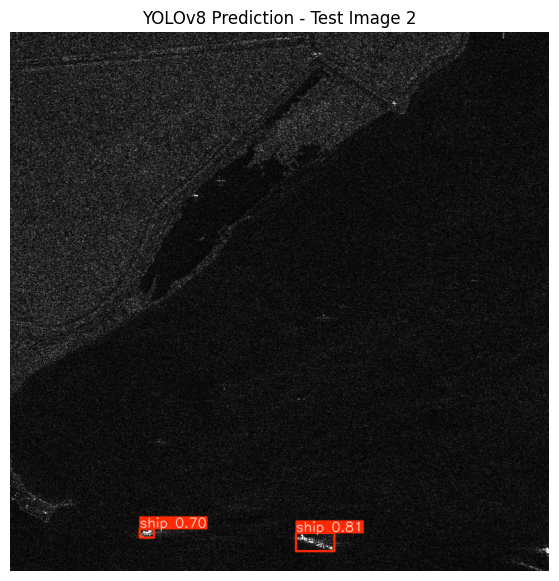

Detected objects:
ship : 0.811
ship : 0.702

Testing image: /content/drive/MyDrive/ResearchProject/dataset/images/test/P0003_1200_2000_7800_8600.png


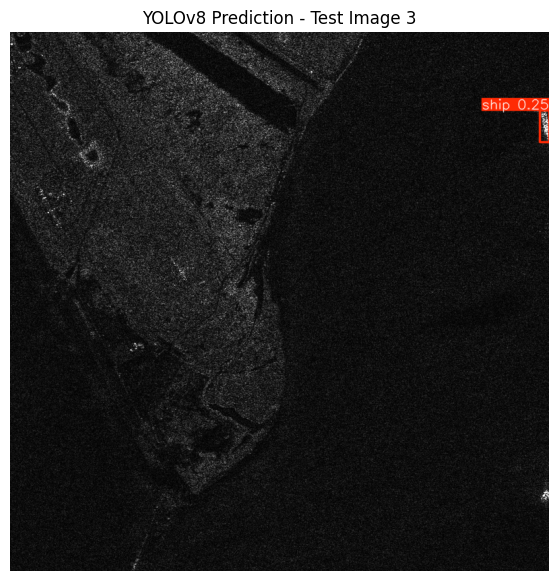

Detected objects:
ship : 0.251

Testing image: /content/drive/MyDrive/ResearchProject/dataset/images/test/P0003_1800_2600_7800_8600.png


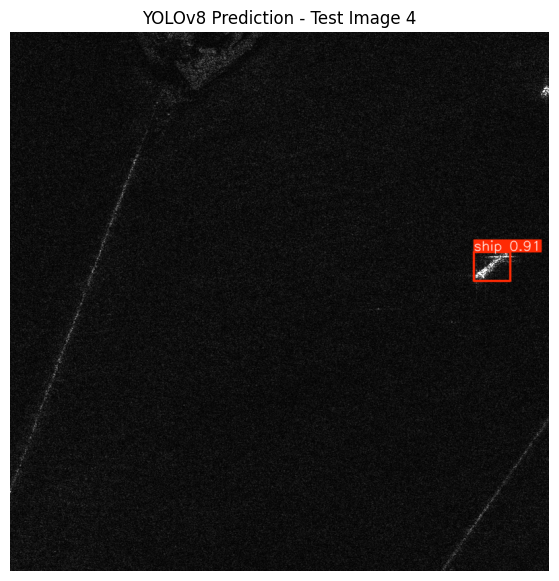

Detected objects:
ship : 0.914

Testing image: /content/drive/MyDrive/ResearchProject/dataset/images/test/P0005_600_1400_7800_8600.png


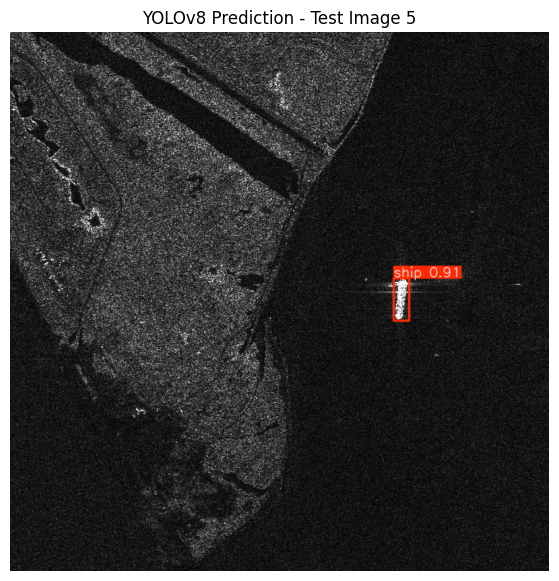

Detected objects:
ship : 0.908


In [15]:
from ultralytics import YOLO
import glob
import matplotlib.pyplot as plt

# Load model
model = YOLO(
    "/content/drive/MyDrive/ResearchProject/results/YOLOv8/weights/best.pt"
)

# Get test images
test_images = sorted(
    glob.glob(
        "/content/drive/MyDrive/ResearchProject/dataset/images/test/*"
    )
)

# Test first 5 images
for i, sample in enumerate(test_images[:5]):

    print("\n" + "="*50)
    print("Testing image:", sample)

    results = model.predict(
        source=sample,
        conf=0.25,
        verbose=False
    )

    # Display result
    img = results[0].plot()

    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"YOLOv8 Prediction - Test Image {i+1}")
    plt.show()

    # Print detections
    print("Detected objects:")

    if len(results[0].boxes) == 0:
        print("No objects detected.")
    else:
        for box in results[0].boxes:
            cls = int(box.cls[0])
            conf = float(box.conf[0])
            print(f"{results[0].names[cls]} : {conf:.3f}")